# Бенчмарк OCR: чем распознавать текст на фото в галерее

Поиск по тексту на картинке работает так: при индексации OCR превращает фото в текст, а запрос `ocrQuery` ищет слова в этом тексте как подстроки. Значит, главный вопрос к OCR: **как часто слово, которое видно на фото, действительно попадает в распознанный текст**.

Сравниваем пять систем на CPU (запуск: `uv run python ocr_bench.py run`):

| Система | Что это |
|---|---|
| `paddle-current` | то, что сейчас в приложении: PP-OCRv5 mobile (поиск текста) + eslav (чтение рус/укр/бел/англ) |
| `paddle-cyrillic` | тот же детектор, другой распознаватель: cyrillic v5 |
| `paddle-server-det` | более тяжёлый серверный детектор + eslav |
| `paddle-v3-cyrillic` | старый распознаватель PP-OCRv3 — показывает, что дало обновление до v5 |
| `easyocr` | популярная альтернатива (ru + en) |

Данные (`make_dataset.py`):
* **синтетика** — 150 картинок 1024×768: русские и английские фразы на однотонном фоне и на реальных фото; пять уровней сложности: `clean` (чистый фон), `photo` (текст на фото), `small` (мелкий текст), `rotated` (поворот 10–25°), `degraded` (размытие, шум, JPEG q=25). Эталон известен точно;
* **реальные фото** — 12 вывесок и дорожных знаков из `test-images`, ключевые слова размечены вручную;
* **«доски»** — 10 картинок с одним словом из `test-images` (то, на чём мы подбирали пороги поиска);
* **фото без текста** — 10 штук, считаем лишние «слова», которые OCR выдумывает (они засоряют поиск).

Метрики: **доля найденных слов** (word recall; как раз то, что делает `ocrQuery`) и **CER** (доля ошибочных символов, меньше — лучше; только синтетика).

> Скорость: основной прогон шёл с 2 потоками, пока на ноутбуке параллельно считался другой бенчмарк, поэтому те миллисекунды завышены. Для сравнения скорости используйте колонку «6 потоков, свободная машина» (`ocr_bench.py speed`, 31 картинка).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ocr_bench as ob

labels, raw = ob.load_all()
df = pd.DataFrame(ob.metrics(labels, raw))
ORDER = [s for s in ob.SYSTEMS if s in raw]
TITLE = {s: ob.SYSTEMS[s]["title"] for s in ORDER}
SHORT = {"paddle-current": "★ paddle-current", "paddle-cyrillic": "paddle-cyrillic", "paddle-server-det": "paddle-server-det",
         "paddle-v3-cyrillic": "paddle-v3-cyrillic", "easyocr": "easyocr"}
COLOR = dict(zip(ob.SYSTEMS, ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00"]))
CONDS = ["clean", "photo", "small", "rotated", "degraded"]
OUT = Path("results"); (OUT / "figures").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "font.size": 10})
def save(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", bbox_inches="tight", dpi=150); plt.show()
SPEED = json.loads((OUT / "speed.json").read_text()) if (OUT / "speed.json").exists() else {}
print("Системы:", ", ".join(ORDER), "| изображений:", df.groupby("system").size().to_dict())

Системы: paddle-current, paddle-cyrillic, paddle-server-det, paddle-v3-cyrillic, easyocr | изображений: {'easyocr': 182, 'paddle-current': 182, 'paddle-cyrillic': 182, 'paddle-server-det': 182, 'paddle-v3-cyrillic': 182}


## 1. Сводная таблица

In [2]:
syn = df[df.group == "synthetic"]
def agg(system):
    d = df[df.system == system]; s = d[d.group == "synthetic"]
    return {
        "Система": SHORT[system],
        "Слова, синтетика ru": s[s.lang == "ru"].word_recall.mean(),
        "Слова, синтетика en": s[s.lang == "en"].word_recall.mean(),
        "CER, ru": s[s.lang == "ru"].cer_dist.sum() / s[s.lang == "ru"].ref_len.sum(),
        "CER, en": s[s.lang == "en"].cer_dist.sum() / s[s.lang == "en"].ref_len.sum(),
        "Слова, реальные фото": d[d.group == "real_photo"].word_recall.mean(),
        "Слова, доски": d[d.group == "real_board"].word_recall.mean(),
        "Лишних слов на фото без текста": d[d.group == "negative"].n_words_pred.mean(),
        "мс/картинку, 2 потока, под нагрузкой": d.ms.median(),
        "мс/картинку, 6 потоков, свободная машина": SPEED.get(system, {}).get("median_ms"),
    }
summary = pd.DataFrame([agg(s) for s in ORDER]).set_index("Система")
summary.round(3)

,"Слова, синтетика ru","Слова, синтетика en","CER, ru","CER, en","Слова, реальные фото","Слова, доски",Лишних слов на фото без текста,"мс/картинку, 2 потока, под нагрузкой","мс/картинку, 6 потоков, свободная машина"
Система,,,,,,,,,
★ paddle-current,0.944,0.954,0.053,0.029,0.681,0.9,2.3,1811.773,1231.221
paddle-cyrillic,0.947,0.954,0.047,0.029,0.553,0.9,2.2,1827.718,1319.310
paddle-server-det,0.998,0.983,0.014,0.023,0.639,0.9,3.2,17069.676,11789.253
paddle-v3-cyrillic,0.407,0.804,0.255,0.090,0.414,0.6,2.7,1195.328,1165.617
easyocr,0.929,0.847,0.073,0.135,0.556,1.0,3.1,6510.513,2447.292


## 2. Синтетика: как зависит от сложности

Доля слов, найденных в распознанном тексте. `clean` — идеальные условия, дальше текст становится мельче, повёрнут или испорчен.

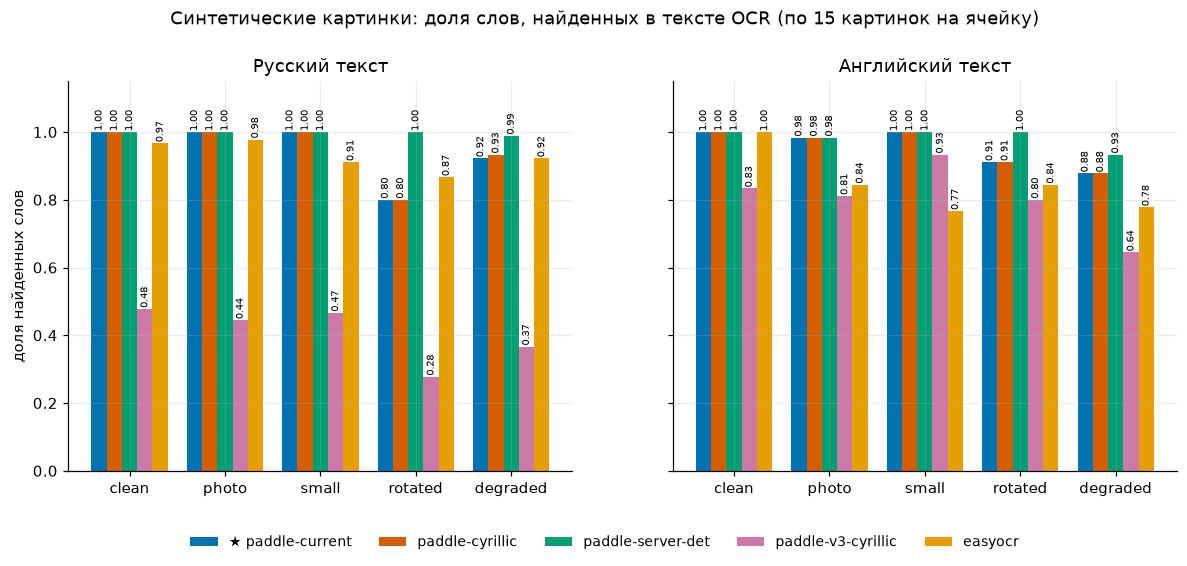

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
w = 0.8 / len(ORDER)
for ax, lang in zip(axes, ["ru", "en"]):
    for j, s in enumerate(ORDER):
        v = [syn[(syn.system == s) & (syn.lang == lang) & (syn.condition == c)].word_recall.mean() for c in CONDS]
        bars = ax.bar(np.arange(len(CONDS)) + (j - (len(ORDER) - 1) / 2) * w, v, w, color=COLOR[s], label=SHORT[s])
        for b, x in zip(bars, v):
            ax.text(b.get_x() + b.get_width() / 2, x + 0.01, f"{x:.2f}", ha="center", fontsize=6.5, rotation=90)
    ax.set_xticks(range(len(CONDS)), CONDS); ax.set_ylim(0, 1.15)
    ax.set_title({"ru": "Русский текст", "en": "Английский текст"}[lang])
axes[0].set_ylabel("доля найденных слов")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.07), frameon=False, fontsize=9)
fig.suptitle("Синтетические картинки: доля слов, найденных в тексте OCR (по 15 картинок на ячейку)", y=1.02)
save(fig, "synthetic_word_recall")

## 3. Ошибки по символам (CER)

Чем темнее и больше число, тем больше ошибок. Для поиска по подстроке важнее доля найденных слов (выше), но CER показывает, насколько «чисто» читается текст.

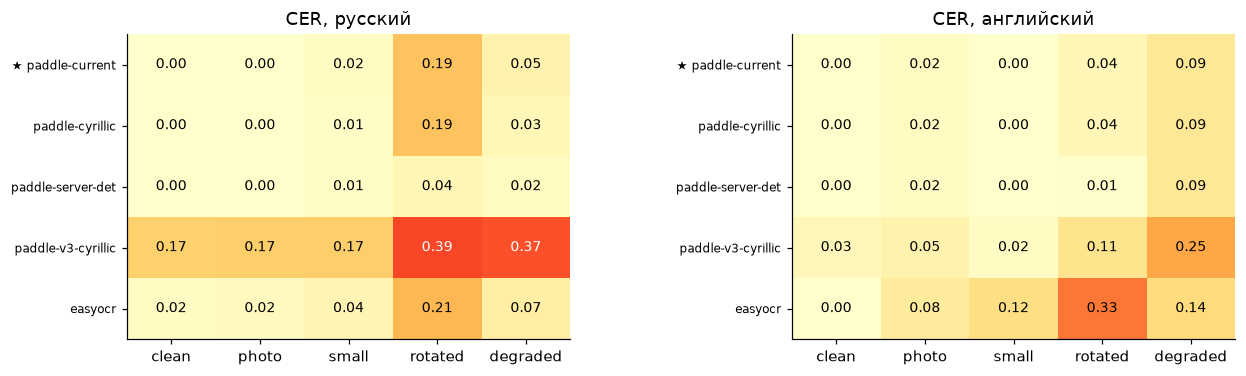

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"wspace": 0.5})
for ax, lang in zip(axes, ["ru", "en"]):
    m = np.array([[syn[(syn.system == s) & (syn.lang == lang) & (syn.condition == c)].cer_dist.sum()
                   / syn[(syn.system == s) & (syn.lang == lang) & (syn.condition == c)].ref_len.sum() for c in CONDS] for s in ORDER])
    im = ax.imshow(m, cmap="YlOrRd", vmin=0, vmax=max(0.6, m.max()), aspect="auto")
    ax.set_xticks(range(len(CONDS)), CONDS); ax.set_yticks(range(len(ORDER)), [SHORT[s] for s in ORDER], fontsize=8)
    ax.grid(False)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if m[i, j] > 0.35 else "black")
    ax.set_title({"ru": "CER, русский", "en": "CER, английский"}[lang])
save(fig, "synthetic_cer")

## 4. Реальные фото: вывески и дорожные знаки

Каждая клетка — доля ключевых слов, найденных на конкретном фото (зелёный — все, красный — ни одного). Здесь шрифты, ракурс, тени и фон настоящие.

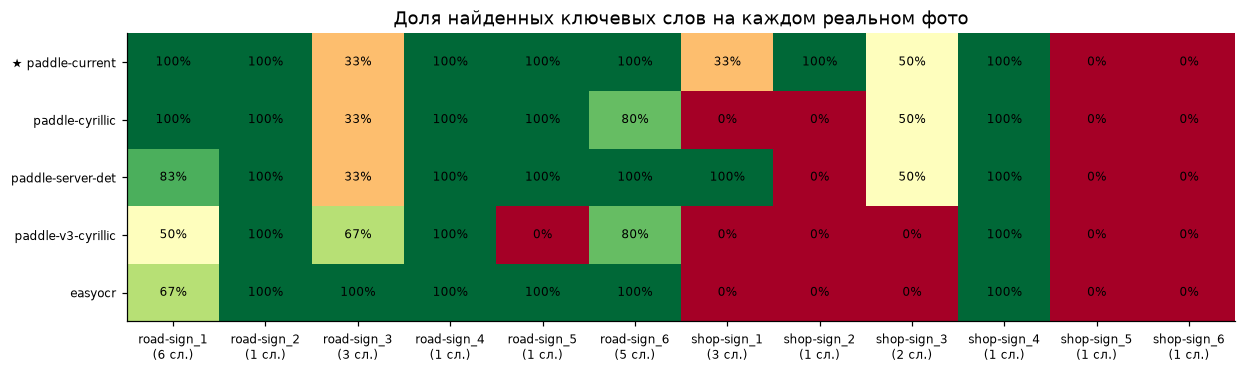

In [5]:
real = df[df.group == "real_photo"].copy()
real["short"] = real.file.map(lambda f: Path(f).stem.replace("ru-", ""))
files = list(real[real.system == ORDER[0]].short)
words = {r.short: r.n_words_ref for r in real[real.system == ORDER[0]].itertuples()}
m = np.array([[real[(real.system == s) & (real.short == f)].word_recall.iloc[0] for f in files] for s in ORDER])
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.imshow(m, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(files)), [f"{f}\n({words[f]} сл.)" for f in files], fontsize=8)
ax.set_yticks(range(len(ORDER)), [SHORT[s] for s in ORDER], fontsize=8)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.text(j, i, f"{m[i, j]:.0%}", ha="center", va="center", fontsize=8)
ax.set_title("Доля найденных ключевых слов на каждом реальном фото")
save(fig, "real_photos")

In [6]:
# Что именно прочитала текущая система на реальных фото (ориентир для разговора об ошибках)
cur = real[real.system == "paddle-current"][["short", "ref", "hyp", "word_recall"]]
pd.set_option("display.max_colwidth", 90)
cur.rename(columns={"short": "фото", "ref": "ключевые слова", "hyp": "распознано", "word_recall": "найдено"}).reset_index(drop=True)

,фото,ключевые слова,распознано,найдено
0,road-sign_1,югорский мост обь длина ширина 2110,р.ОБЬ | ЮГОРСКИЙ | MOCT | ДЛИНА | 2110M | ШИРИНА | 14M | род | МОСТЫХМАО | ПОСТРОЙКИ: ...,1.000000
1,road-sign_2,двуречье,ДВУРЕЧЬЕ,1.000000
2,road-sign_3,красноармейск дмитров ногинск,KPACHOAPMEЙCK | ДМИТРОВ | HOFИHCK | A107 | A 107 | 300M,0.333333
3,road-sign_4,плешаковский,ПЛЕШАКОВСКИЙ,1.000000
4,road-sign_5,полчаниновка,ПОЛЧАНИНОВКА,1.000000
5,road-sign_6,церковь троицы живоначальной church trinity,"0,3 | Церковь Троицы Живоначальной | Church of the Life-Giving Trinity",1.000000
6,shop-sign_1,товары повседневного спроса,КУНДЕМКТИ | KOOC | 7 | KАЖEТ | 1 | X | БУЙЫМДАРЫ | СПРОСА | COOLED BY | Valeo,0.333333
7,shop-sign_2,продовольственный,ПРОДОВОЛЬСТВЕННЫЙ,1.000000
8,shop-sign_3,магазин спутник,МАГАЗИН | H | 6 | 6,0.500000
9,shop-sign_4,спирт,b3n | СПИРТ,1.000000


## 5. Качество против скорости, и лишние слова

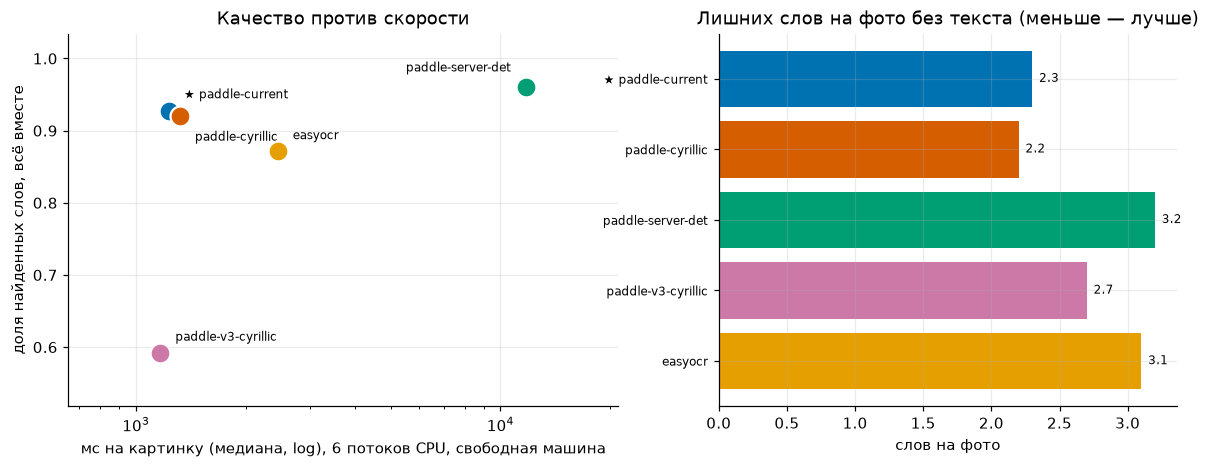

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
for s in ORDER:
    d = df[df.system == s]
    q = d[d.group.isin(["synthetic", "real_photo", "real_board"])].word_recall.mean()
    x = SPEED[s]["median_ms"] if s in SPEED else d.ms.median()
    a1.scatter(x, q, s=170, color=COLOR[s], edgecolor="white", linewidth=1.5, zorder=3)
    off = {"paddle-cyrillic": (10, -16), "paddle-server-det": (-10, 10)}.get(s, (10, 8))
    a1.annotate(SHORT[s], (x, q), textcoords="offset points", xytext=off, fontsize=8,
                ha="right" if off[0] < 0 else "left")
a1.set_xscale("log")
a1.set_xlabel("мс на картинку (медиана, log)" + (", 6 потоков CPU, свободная машина" if SPEED else ", 2 потока, под нагрузкой"))
a1.set_ylabel("доля найденных слов, всё вместе")
a1.set_title("Качество против скорости"); a1.margins(x=0.25, y=0.2)

junk = [df[(df.system == s) & (df.group == "negative")].n_words_pred.mean() for s in ORDER]
bars = a2.barh(range(len(ORDER))[::-1], junk, color=[COLOR[s] for s in ORDER])
a2.set_yticks(range(len(ORDER))[::-1], [SHORT[s] for s in ORDER], fontsize=8)
for b, v in zip(bars, junk): a2.text(v + 0.05, b.get_y() + b.get_height() / 2, f"{v:.1f}", va="center", fontsize=8)
a2.set_title("Лишних слов на фото без текста (меньше — лучше)"); a2.set_xlabel("слов на фото")
save(fig, "speed_vs_quality")

## 6. Выводы

Данные: 150 синтетических картинок, 12 реальных вывесок/знаков, 10 «досок», 10 фото без текста; CPU AMD Ryzen 5 5600H, без GPU. Скорость в таблице — на свободной машине, 6 потоков (30 картинок).

1. **Текущая система (`PP-OCRv5 mobile` + `eslav`) — разумный выбор по соотношению качества и цены.** Она находит 94% русских и 95% английских слов на синтетике, 68% ключевых слов на реальных фото (лучший результат из пяти) и 90% на «досках». Обрабатывает картинку за ~1,2 с.
2. **Серверный детектор даёт больше, но стоит в 10 раз дороже.** `paddle-server-det` находит 99,8% русских слов (против 94,4%) и читает повёрнутый текст (на русском `rotated`: 100% против 80%), но тратит ~11,8 с на картинку вместо ~1,2 с. На реальных фото он не лучше (64% против 68%) и выдаёт больше мусора на фото без текста (3,2 слова против 2,3). Для локальной индексации галереи на CPU такая цена не оправдана; имеет смысл только как опция при наличии GPU.
3. **EasyOCR хуже и медленнее.** ~2,4 с на картинку (вдвое дольше), на английском находит 85% слов (против 95%), на реальных фото — 56%. Единственное, где он впереди, — «доски» (100% против 90%, это одно слово из десяти).
4. **Другой распознаватель PaddleOCR не лучше.** `cyrillic v5` на синтетике ничем не отличается от `eslav` (94,7% против 94,4%), а на реальных фото хуже (55% против 68%): разница в три фото, но выигрыша нет. `cyrillic v3` (прошлое поколение) читает русский вдвое хуже (41% слов), так что обновление до v5 важно.
5. **Слабое место — не выбор модели, а стилизованные вывески.** На шести реальных вывесках магазинов (рукописный и фигурный шрифт, надписи на изогнутой подложке) все системы находят слова лишь на 2–3 из шести фото. Это видно на тепловой карте выше, и этого не исправить сменой OCR из списка.

Что учесть:
* Реальных фото всего 12 и «досок» 10: одно фото — это 8 п.п., так что разницу в 5–10 п.п. между системами на реальных фото нельзя считать надёжной. Выводы 1–4 опираются в основном на синтетику (150 картинок) и на разницу в скорости.
* Синтетика проще реальности: шрифты Windows, текст читаемый; зато она показывает, как падает качество от поворота, размытия и мелкого текста.
* Ключевые слова реальных фото размечены вручную (`real_labels.json`); «промтовар» записано как основа слова, потому что на фото конец слова читается неоднозначно.
* CER считается по лучшему совпадающему фрагменту распознанных строк, поэтому текст на заднем плане фото ошибкой не считается.
* Для каждой картинки в приложении OCR (~1,2 с) примерно в пять раз дороже, чем кодирование CLIP-моделью B/16 (~0,25 с): индексация идёт в основном на OCR.

In [8]:
summary.round(4).to_csv(OUT / "summary.csv")
df.drop(columns=["cer_dist", "ref_len"]).to_csv(OUT / "per_image.csv", index=False)
print("Сохранено:", OUT / "summary.csv", OUT / "per_image.csv")

Сохранено: results\summary.csv results\per_image.csv
